   # CardioPredict AI · Tamizaje de riesgo de cardiopatía

   **Proyecto ACA 1 · Aprendizaje Automático** · Especialización en Inteligencia Artificial (CUN)

   **Curso:** APRENDIZAJE AUTOMÁTICO/54ES2/SEGUNDO BLOQUE/26ES4 ·
   
   **Docente:** Dr. Hamilton Rivera Flor
   
   **Autora:** Claudia Teresa Aranguren Peña
   
   **App:** https://cardiopredict-ai-ctap.streamlit.app ·
   
   **Video:** https://youtu.be/FbgWG-W6Ia4

#**Justificación y Origen del Esquema de Datos Clínicos**

## **¿De dónde surgen los nombres de las columnas?**

Al inspeccionar el archivo original de datos (`processed.cleveland.data`), se evidencia que **no contiene una fila inicial con los nombres de las columnas** (encabezados). En su lugar, el archivo inicia de inmediato con los registros numéricos de los pacientes separados por comas:

> **Ejemplo de la primera línea en bruto:**  
> `63.0, 1.0, 1.0, 145.0, 233.0, 1.0, 2.0, 150.0, 0.0, 2.3, 3.0, 0.0, 6.0, 0`

Si se importara este archivo sin especificar las columnas, la librería *Pandas* tomaría al primer paciente como título o crearía índices numéricos anónimos (`0, 1, 2, ...`).

Para otorgar una semántica médica formal, se asignó la lista de variables basándose estrictamente en el diccionario de datos oficial del repositorio **UCI Machine Learning Repository**: el archivo **`heart-disease.names`** (sección *7. Attribute Information*).

El conjunto de datos seleccionado corresponde al repositorio Heart Disease Cleveland de UCI Machine Learning Repository, ampliamente utilizado en investigación académica y enseñanza de Machine Learning para problemas de clasificación médica. El objetivo del proyecto consiste en desarrollar un modelo predictivo capaz de identificar la presencia de cardiopatías a partir de biomarcadores clínicos obtenidos durante la valoración de pacientes. Debido a que el dataset contiene variables fisiológicas, resultados de pruebas diagnósticas y una etiqueta clínica asociada al diagnóstico, constituye un caso adecuado para la aplicación de algoritmos clásicos de clasificación supervisada.

A continuación se detalla la correspondencia de los 14 biomarcadores clínicos:

| N° | Variable Original UCI | Nombre en nuestro Dataset | Descripción Clínica del Parámetro |
| :---: | :--- | :--- | :--- |
| **1** | `age` | `edad` | Edad del paciente en años cumplidos. |
| **2** | `sex` | `sexo` | Sexo biológico (1 = masculino, 0 = femenino). |
| **3** | `cp` | `tipo_dolor_pecho` | Tipo de dolor torácico (1: angina típica, 2: angina atípica, 3: dolor no anginoso, 4: asintomático). |
| **4** | `trestbps` | `presion_reposo` | Presión arterial sistólica en reposo al ingresar al hospital (en mm Hg). |
| **5** | `chol` | `colesterol` | Nivel de colesterol sérico total (en mg/dl). |
| **6** | `fbs` | `azucar_ayunas` | Glucemia en ayunas > 120 mg/dl (1 = verdadero, 0 = falso). |
| **7** | `restecg` | `electro_reposo` | Electrocardiograma en reposo (0: normal, 1: onda ST-T anormal, 2: hipertrofia ventricular). |
| **8** | `thalach` | `frecuencia_max` | Frecuencia cardíaca máxima alcanzada durante la prueba de esfuerzo. |
| **9** | `exang` | `angina_ejercicio` | Angina de pecho inducida por el ejercicio (1 = sí, 0 = no). |
| **10** | `oldpeak` | `depresion_st` | Depresión del segmento ST inducida por esfuerzo con respecto al reposo. |
| **11** | `slope` | `pendiente_st` | Pendiente del segmento ST en el punto máximo de esfuerzo (1: ascendente, 2: plana, 3: descendente). |
| **12** | `ca` | `num_vasos_principales` | Número de vasos coronarios principales coloreados por fluoroscopia (de 0 a 3). |
| **13** | `thal` | `talasemia` | Estado de perfusión sanguínea y talasemia (3: normal, 6: defecto fijo, 7: defecto reversible). |
| **14** | `num` (target) | `objetivo` | Diagnóstico de cardiopatía (0: ausencia/sano, 1 a 4: presencia con distintos grados). |

> **Nota de preprocesamiento:** Los nombres de las variables fueron traducidos a términos descriptivos en español con el fin de facilitar la interpretación clínica, la comprensión de las visualizaciones exploratorias y la construcción de la aplicación final en Streamlit. Adicionalmente, la variable objetivo original fue transformada en una variable binaria (0 = Sano, 1 = Cardiopatía), simplificando el problema a una tarea de clasificación supervisada binaria, acorde con los algoritmos estudiados en el curso.

Como resultado de esta fase se obtuvo un conjunto de datos clínicos estructurado, documentado y adaptado al contexto del proyecto, garantizando una correcta interpretación de las variables en las etapas posteriores de limpieza, análisis exploratorio y entrenamiento de modelos predictivos.

#**Carga, Estructuración y Binarización de Datos**

In [ ]:

# IMPORTAR LIBRERÍAS


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gdown

# Estilo visual limpio para los gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)


#DESCARGA DESDE GOOGLE DRIVE

file_id = "1Qtl9qfCO7bYckOdq2yIvujS-pAfEBg9l"
url_descarga = f"https://drive.google.com/uc?id={file_id}"
archivo_local = "processed.cleveland.data"

# Descarga el archivo del Drive a Colab
gdown.download(url_descarga, archivo_local, quiet=False)

# Nombres formales de las 14 columnas clínicas del problema
columnas = [
    'edad', 'sexo', 'tipo_dolor_pecho', 'presion_reposo', 'colesterol',
    'azucar_ayunas', 'electro_reposo', 'frecuencia_max', 'angina_ejercicio',
    'depresion_st', 'pendiente_st', 'num_vasos_principales', 'talasemia', 'objetivo'
]

# Leer el archivo asignando NaN a los valores '?'
df = pd.read_csv(archivo_local, names=columnas, na_values="?")

# Binarizar la variable objetivo:
# 0 = Sin enfermedad cardíaca (Sano)
# 1 = Con presencia de afección cardíaca
df['objetivo'] = df['objetivo'].apply(lambda x: 1 if x > 0 else 0)

print("\n" + "="*50)
print(f"✅ ¡Dataset cargado exitosamente el Drive!")
print(f"Total de registros: {df.shape[0]} pacientes")
print(f"Total de características: {df.shape[1] - 1} biomarcadores clínicos + 1 objetivo")
print("="*50)
df.head()

Downloading...
From: https://drive.google.com/uc?id=1Qtl9qfCO7bYckOdq2yIvujS-pAfEBg9l
To: /content/processed.cleveland.data
100%|██████████| 18.5k/18.5k [00:00<00:00, 31.4MB/s]


✅ ¡Dataset cargado exitosamente el Drive!
Total de registros: 303 pacientes
Total de características: 13 biomarcadores clínicos + 1 objetivo


,edad,sexo,tipo_dolor_pecho,presion_reposo,colesterol,azucar_ayunas,electro_reposo,frecuencia_max,angina_ejercicio,depresion_st,pendiente_st,num_vasos_principales,talasemia,objetivo
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
#AUDITORÍA INICIAL DEL DATASET

print("="*60)
print("INFORMACIÓN GENERAL DEL DATASET")
print("="*60)

df.info()

print("\n" + "="*60)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("="*60)

display(df.describe())

print("\n" + "="*60)
print("VERIFICACIÓN DE DUPLICADOS")
print("="*60)

duplicados = df.duplicated().sum()

print(f"Registros duplicados encontrados: {duplicados}")

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad                   303 non-null    float64
 1   sexo                   303 non-null    float64
 2   tipo_dolor_pecho       303 non-null    float64
 3   presion_reposo         303 non-null    float64
 4   colesterol             303 non-null    float64
 5   azucar_ayunas          303 non-null    float64
 6   electro_reposo         303 non-null    float64
 7   frecuencia_max         303 non-null    float64
 8   angina_ejercicio       303 non-null    float64
 9   depresion_st           303 non-null    float64
 10  pendiente_st           303 non-null    float64
 11  num_vasos_principales  299 non-null    float64
 12  talasemia              301 non-null    float64
 13  objetivo               303 non-null    int64  
dtypes: float64(13), int64(1)
m

,edad,sexo,tipo_dolor_pecho,presion_reposo,colesterol,azucar_ayunas,electro_reposo,frecuencia_max,angina_ejercicio,depresion_st,pendiente_st,num_vasos_principales,talasemia,objetivo
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000



VERIFICACIÓN DE DUPLICADOS
Registros duplicados encontrados: 0


##**Auditoría Inicial del Dataset**

**¿Por qué se realizó esta rutina? (Propósito y Justificación Técnica)**

Antes de realizar cualquier procedimiento de limpieza o entrenamiento de modelos predictivos, es indispensable efectuar una auditoría inicial del conjunto de datos. Esta etapa permite comprender la estructura del dataset, identificar los tipos de variables disponibles, detectar posibles inconsistencias y evaluar si los datos cumplen las condiciones mínimas de calidad requeridas por los algoritmos de Machine Learning.

Para ello se utilizaron tres procedimientos fundamentales:

* df.info(), con el fin de inspeccionar la estructura general del conjunto de datos, la cantidad de registros disponibles y los tipos de datos asignados a cada variable.

* df.describe(), para obtener estadísticas descriptivas básicas de las variables numéricas, tales como media, desviación estándar, valores mínimos y máximos.

* df.duplicated().sum(), con el propósito de verificar la existencia de registros completamente repetidos que pudieran sesgar el entrenamiento y la evaluación posterior de los modelos predictivos.

Esta fase constituye una práctica recomendada dentro del proceso CRISP-DM y de los flujos modernos de Ciencia de Datos, ya que permite detectar problemas potenciales antes de iniciar el preprocesamiento formal de la información.

**Interpretación de resultados**

La auditoría inicial confirma la correcta carga del conjunto de datos clínicos procedente del repositorio Cleveland Heart Disease. La inspección estructural permite verificar que las variables predictoras y la variable objetivo fueron importadas satisfactoriamente en formatos numéricos compatibles con los algoritmos de Machine Learning.

De igual manera, las estadísticas descriptivas permiten validar que las mediciones clínicas presentan rangos fisiológicamente plausibles para variables como edad, presión arterial, colesterol sérico y frecuencia cardíaca máxima alcanzada durante la prueba de esfuerzo.

Finalmente, la verificación de duplicados permite determinar si existen registros repetidos que puedan introducir sesgos estadísticos. La verificación arrojó 0 registros duplicados, lo que confirma que cada fila representa un paciente distinto dentro del estudio.

In [ ]:
# DIAGNÓSTICO DE VALORES NULOS (sin imputar)
# La imputación se hará después de dividir los datos en entrenamiento y prueba,
# para que el conjunto de prueba no influya en los valores de relleno.

nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)

tabla_nulos = pd.DataFrame({"Valores nulos": nulos, "% del total": porcentaje})
display(tabla_nulos[tabla_nulos["Valores nulos"] > 0])

print(f"Total de celdas vacías en el dataset: {nulos.sum()}")

,Valores nulos,% del total
num_vasos_principales,4,1.32
talasemia,2,0.66


Total de celdas vacías en el dataset: 6


#Diagnóstico de Valores Faltantes

 **1. ¿Por qué se realizó esta rutina? (Propósito y Justificación)**

 * **Principio de Calidad de Datos (Garbage in, Garbage out):**
  
    En Machine Learning, un modelo matemático no puede aprender patrones confiables si se alimenta con datos incompletos o con huecos vacíos. Además, la gran mayoría de algoritmos clásicos (como la Regresión Logística o KNN) arrojan un error de ejecución inmediato si encuentran valores nulos (NaN).

  * **Identificación de vacíos:**
  Primero se ejecutó df.isnull().sum() para auditar columna por columna cuántos datos faltaban en el conjunto de pacientes.   

  Decisión de imputación diferida: Los valores faltantes no se imputan en esta etapa. Si la moda se calculara con los 303 pacientes, incluiría información del futuro conjunto de prueba (data leakage). Por eso la imputación se realizará dentro de un pipeline, ajustado únicamente con los datos de entrenamiento. Se usará la moda (most_frequent) porque ambas variables son discretas: un promedio podría producir valores sin sentido clínico, como “0.67 vasos”.

**2. Análisis e Interpretación de los Resultados**
  * **Baja tasa de datos faltantes:**
  
    La auditoría reveló que el conjunto de datos cuenta con una integridad clínica sobresaliente. De los 303 pacientes y las 14 variables analizadas, únicamente dos columnas presentaron omisiones:

    * num_vasos_principales: 4 valores nulos (representa apenas el $1.3\%$ de los pacientes).
    * talasemia: 2 valores nulos (apenas el $0.6\%$ de los pacientes).
    * Las 12 variables restantes tienen sus 303 registros completos al $100\%$.

Conclusión: Solo 6 de las 4.242 celdas del dataset están vacías (0.14%). Se conservan los 303 pacientes, y los vacíos se resolverán después de la partición de datos.

#Exploración Visual Básica (EDA) y Diagnóstico de Balanceo de Clases

Pacientes Sanos (0): 164 (54.1%)
Pacientes con Cardiopatía (1): 139 (45.9%)


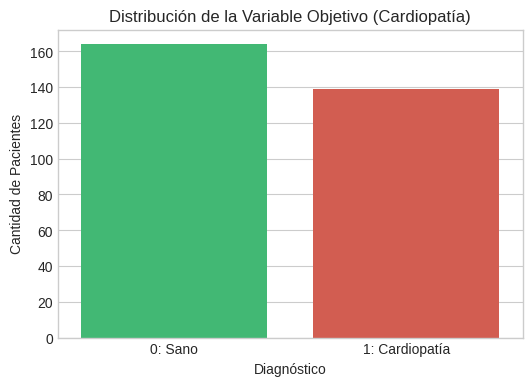

In [ ]:
# EXPLORACIÓN DE LA VARIABLE OBJETIVO

conteo = df['objetivo'].value_counts()
print(f"Pacientes Sanos (0): {conteo[0]} ({conteo[0]/len(df)*100:.1f}%)")
print(f"Pacientes con Cardiopatía (1): {conteo[1]} ({conteo[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='objetivo', hue='objetivo', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title("Distribución de la Variable Objetivo (Cardiopatía)")
plt.xticks([0, 1], ['0: Sano', '1: Cardiopatía'])
plt.xlabel("Diagnóstico")
plt.ylabel("Cantidad de Pacientes")
plt.show()

**1. ¿Por qué se realizó esta rutina? (Propósito y Justificación)**

* **Auditoría de la variable dependiente (objetivo):** En problemas de clasificación supervisada, antes de entrenar cualquier modelo matemático es obligatorio analizar la distribución de la variable a predecir.   
* **Detección de sesgo o desbalance severo:** Si una clase tuviera el $95\%$ de los registros y la otra solo el $5\%$, el modelo aprendería un sesgo tramposo (predecir siempre la clase mayoritaria para obtener alta exactitud aparente sin aprender nada real). Saber si el conjunto de datos está balanceado define si se requieren técnicas avanzadas de remuestreo sintético (como SMOTE) o si se puede proceder de forma directa.   
* **Verificación de métricas adecuadas:** El balanceo de clases determina qué métricas de desempeño serán confiables: en conjuntos equilibrados, métricas como el Accuracy (Exactitud global) son válidas y comparables junto al Recall y F1-Score.   
* **Representación gráfica:** Mediante seaborn.countplot(), se genera una gráfica de barras con codificación visual intuitiva (verde para pacientes sanos y rojo para pacientes con presencia de cardiopatía) para facilitar la comunicación del problema a perfiles no técnicos o evaluadores.

**2. Análisis e Interpretación de los Resultados**
* **Distribución cuantitativa de los pacientes:**

  * Clase 0 (Sanos): 164 pacientes, equivalente al $54.1\%$ de la muestra.   
  * Clase 1 (Con Cardiopatía): 139 pacientes, equivalente al $45.9\%$ de la muestra.   
  * Total evaluado: 303 pacientes.   
  
* **Diagnóstico: Conjunto de datos balanceado:**

  * La diferencia entre ambas clases es de apenas $8.2$ puntos porcentuales (una relación cercana a $1.18 : 1$).   
  * Conclusión técnica: No existe un desbalance de clases significativo. Por lo tanto, no es necesario aplicar técnicas artificiales de sobremuestreo ni submuestreo que puedan alterar la varianza natural del estudio.   
* **Implicación para el modelado:**
  * Al momento de dividir los datos en entrenamiento y prueba (train_test_split), bastará con usar el parámetro stratify=y para asegurar que esta proporción original ($\approx 54\%$ vs. $\approx 46\%$) se conserve intacta en ambos conjuntos.   

##**Análisis Exploratorio de Biomarcadores Clínicos**

### **Distribución de los biomarcadores numéricos**

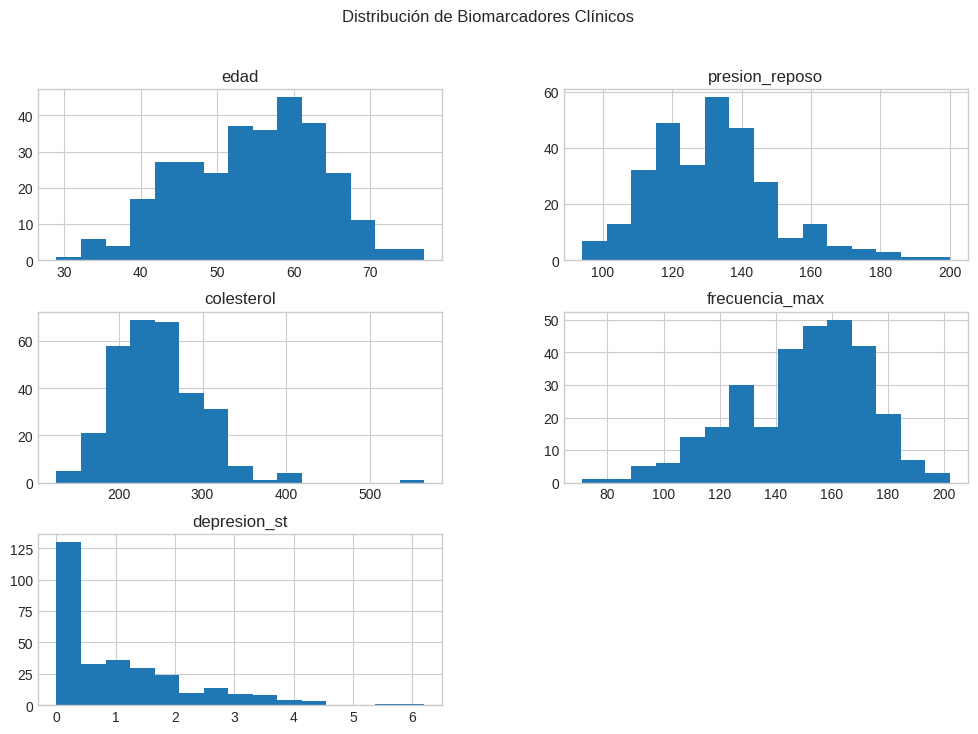

In [ ]:
df[['edad',
    'presion_reposo',
    'colesterol',
    'frecuencia_max',
    'depresion_st']].hist(
        figsize=(12,8),
        bins=15
)

plt.suptitle("Distribución de Biomarcadores Clínicos")
plt.show()

**Análisis e Interpretación de los Resultados**

* **Edad, presión arterial en reposo y colesterol** presentan distribuciones aproximadamente simétricas, con una leve asimetría a la derecha en presión y colesterol, causada por algunos valores altos.
* **Frecuencia cardíaca máxima:** muestra asimetría a la izquierda: la mayoría de los pacientes alcanza valores altos y unos pocos presentan valores muy bajos.
* **Depresión del segmento ST** tiene una fuerte asimetría a la derecha: muchos pacientes registran 0 y pocos alcanzan valores altos.
* Estas diferencias de forma y de escala justifican el uso de la **mediana** para imputar (robusta ante asimetrías) y del **escalado estándar** antes de entrenar modelos sensibles a la magnitud de las variables.

### **Matriz de correlación**

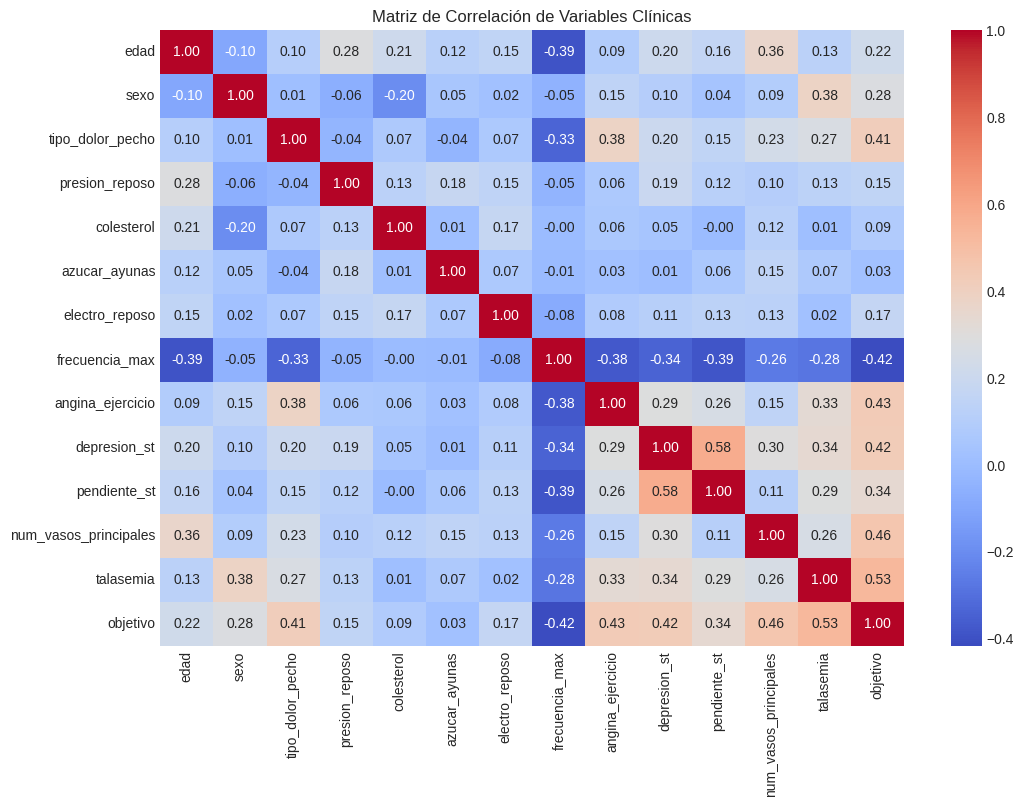

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de Correlación de Variables Clínicas")
plt.show()

**Análisis e Interpretación de los Resultados**

La matriz de correlación permitió identificar las relaciones existentes entre los biomarcadores clínicos y la variable objetivo asociada a la presencia de cardiopatía. Entre las variables con mayor asociación positiva se encuentran la talasemia, el número de vasos coronarios principales y la angina inducida por ejercicio, lo que sugiere que estas características presentan una relación importante con la probabilidad de enfermedad cardíaca dentro de la población analizada.

Por otra parte, la frecuencia cardíaca máxima alcanzada presenta una correlación negativa con la variable objetivo, indicando que valores más elevados de frecuencia máxima suelen asociarse con una menor probabilidad de cardiopatía en este conjunto de datos. Este comportamiento muestra una relación inversa entre ambas variables y sugiere que la respuesta cardiovascular durante el esfuerzo físico podría aportar información relevante para la clasificación de pacientes.

Limitación del análisis: la correlación de Pearson mide relaciones lineales entre variables numéricas continuas. En variables nominales como talasemia o tipo_dolor_pecho, sus coeficientes dependen de la codificación arbitraria de las categorías y deben interpretarse con cautela. Por esta razón, el análisis se complementa con la comparación de porcentajes por categoría presentada más adelante.

##**Variables numéricas según diagnóstico**

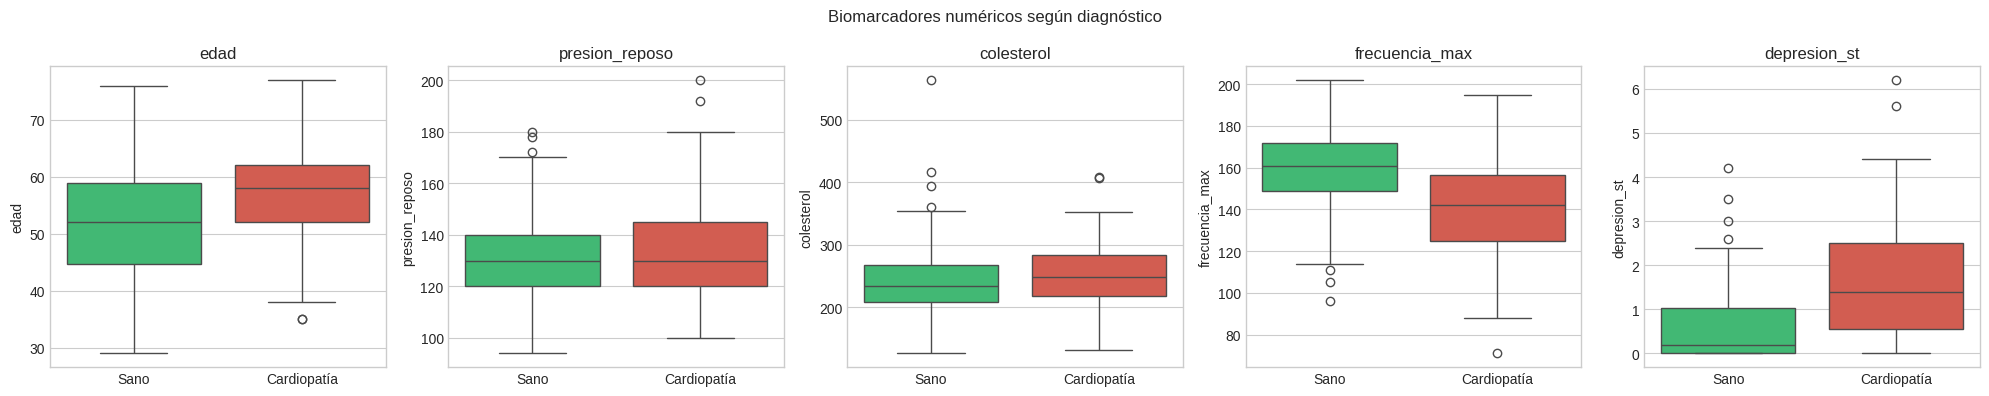

In [ ]:
# ANÁLISIS BIVARIADO: BIOMARCADORES NUMÉRICOS VS DIAGNÓSTICO
# Compara la distribución de cada variable entre pacientes sanos y con cardiopatía.
# Si las cajas están desplazadas entre sí, la variable ayuda a separar los grupos.

numericas = ['edad', 'presion_reposo', 'colesterol', 'frecuencia_max', 'depresion_st']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(data=df, x='objetivo', y=col, hue='objetivo',
                palette=['#2ecc71', '#e74c3c'], legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xticks([0, 1], ['Sano', 'Cardiopatía'])
    ax.set_xlabel('')

plt.suptitle('Biomarcadores numéricos según diagnóstico')
plt.tight_layout()
plt.show()

**Análisis e Interpretación de los Resultados**

Se comparó la distribución de cada biomarcador numérico entre pacientes sanos y con cardiopatía:

* **Frecuencia cardíaca máxima:** es la variable que mejor separa los grupos. La mediana de los sanos (≈161 lpm) es claramente mayor que la de los enfermos (≈142 lpm). Esto es coherente con la clínica: un corazón con enfermedad coronaria tolera menos el esfuerzo.
* **Depresión del segmento ST:** los enfermos presentan valores mucho más altos (mediana ≈1.4 frente a ≈0.2 en sanos). Una mayor depresión del ST durante el esfuerzo es un signo clásico de isquemia.
* **Edad:** los pacientes con cardiopatía tienden a ser mayores (mediana ≈58 frente a ≈52 años), aunque las cajas se superponen parcialmente.
* **Presión arterial en reposo y colesterol:** las cajas de ambos grupos casi coinciden (medianas muy similares). Por sí solas, estas variables aportan poca capacidad de separación en esta muestra.

**Valores atípicos:** se observan algunos casos extremos, como un colesterol de 564 mg/dl o una presión de 200 mm Hg. Se decidió conservarlos, porque son clínicamente posibles y no errores de digitación. Además, eliminarlos reduciría una muestra que ya es pequeña (303 pacientes).

## **Variables categóricas según diagnóstico**

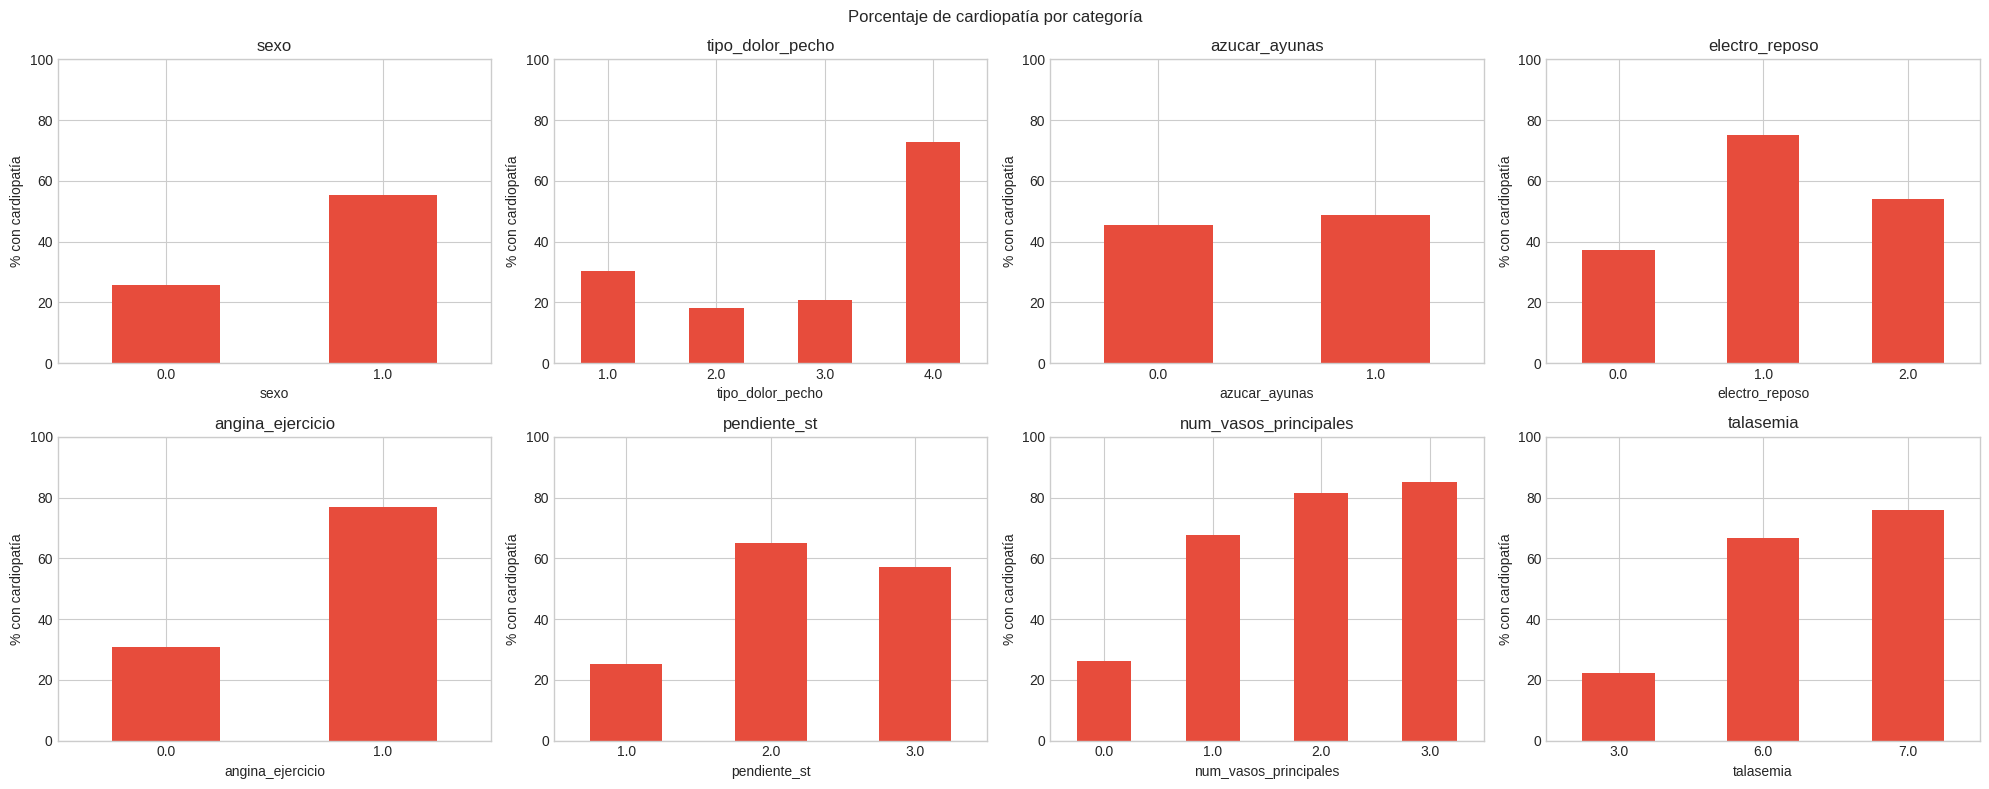

In [ ]:
# ANÁLISIS BIVARIADO: VARIABLES CATEGÓRICAS VS DIAGNÓSTICO
# Para cada categoría se calcula el porcentaje de pacientes con cardiopatía.
# Barras de alturas muy distintas indican que la variable aporta información.
# (Los 6 valores vacíos se excluyen automáticamente de este conteo.)

categoricas = ['sexo', 'tipo_dolor_pecho', 'azucar_ayunas', 'electro_reposo',
               'angina_ejercicio', 'pendiente_st', 'num_vasos_principales', 'talasemia']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flatten(), categoricas):
    tasa = df.groupby(col)['objetivo'].mean() * 100
    tasa.plot(kind='bar', ax=ax, color='#e74c3c')
    ax.set_title(col)
    ax.set_ylabel('% con cardiopatía')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)

plt.suptitle('Porcentaje de cardiopatía por categoría')
plt.tight_layout()
plt.show()

**Análisis e Interpretación de los Resultados**

Para cada categoría se calculó el porcentaje de pacientes con cardiopatía. Como referencia, el promedio general del dataset es 45.9%.

* **Variables con alta capacidad de separación:**
  * **Número de vasos principales:** el riesgo aumenta de forma escalonada, desde ≈26% con 0 vasos hasta ≈85% con 3 vasos.
  * **Talasemia:** ≈22% con resultado normal (3), frente a ≈67% con defecto fijo (6) y ≈76% con defecto reversible (7).
  * **Tipo de dolor torácico:** los pacientes asintomáticos (4) concentran el mayor riesgo (≈73%). Parece contraintuitivo, pero se explica porque la enfermedad coronaria puede cursar sin dolor (isquemia silente).
  * **Angina inducida por ejercicio:** ≈77% con angina frente a ≈31% sin ella.
* **Variables con separación moderada:** el sexo (≈55% en hombres frente a ≈26% en mujeres) y la pendiente del ST (≈25% con pendiente ascendente frente a ≈57–65% con pendiente plana o descendente).
* **Variable con baja capacidad de separación:** la glucemia en ayunas (≈45% frente a ≈49%), con alturas casi iguales.
* **Precaución con el electrocardiograma en reposo:** la categoría 1 (anomalía ST-T) muestra ≈75%, pero solo tiene **4 pacientes.** Con tan pocos casos, ese porcentaje no es confiable.

Implicación para el modelado: variables como tipo_dolor_pecho, talasemia, electro_reposo y pendiente_st son categóricas nominales: sus números son etiquetas, no cantidades. Por ejemplo, talasemia = 7 no significa “más” que 6. Por eso, en la etapa de preparación se transformarán con One-Hot Encoding.

#**Preparación de Datos (Partición y Pipeline de Preprocesamiento)**

In [ ]:
# PREPARACIÓN DE DATOS: PARTICIÓN Y PIPELINE DE PREPROCESAMIENTO
# Todo el preprocesamiento se encapsula en un ColumnTransformer que se ajusta
# SOLO con los datos de entrenamiento, para evitar fuga de información.

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Separar características (X) y variable objetivo (y)
#    X conserva los 6 valores vacíos: se imputarán dentro del pipeline.
X = df.drop('objetivo', axis=1)
y = df['objetivo']

# 2. Partición estratificada 80/20 (antes de cualquier imputación o escalado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Clasificación de variables según su naturaleza
continuas  = ['edad', 'presion_reposo', 'colesterol', 'frecuencia_max', 'depresion_st']
ordinales  = ['num_vasos_principales']
binarias   = ['sexo', 'azucar_ayunas', 'angina_ejercicio']
nominales  = ['tipo_dolor_pecho', 'electro_reposo', 'pendiente_st', 'talasemia']

# 4. Transformación de cada grupo
preprocesador = ColumnTransformer(transformers=[
    ('cont', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),        # robusta ante atípicos
        ('escalar', StandardScaler())
    ]), continuas),
    ('ord', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')), # conteo discreto (0-3)
        ('escalar', StandardScaler())
    ]), ordinales),
    ('bin', 'passthrough', binarias),                          # ya están en 0/1
    ('nom', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')), # moda: valores discretos
        ('onehot', OneHotEncoder(handle_unknown='ignore'))    # etiquetas, no cantidades
    ]), nominales),
])

# 5. Verificación: ajustar con entrenamiento y transformar ambos conjuntos
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep  = preprocesador.transform(X_test)

print(f"Pacientes de entrenamiento: {X_train.shape[0]} | de prueba: {X_test.shape[0]}")
print(f"Columnas originales: {X_train.shape[1]} | tras el preprocesamiento: {X_train_prep.shape[1]}")
print(f"Valores vacíos tras el pipeline: {pd.isna(X_train_prep).sum() + pd.isna(X_test_prep).sum()}")
print("\nCaracterísticas finales:")
print(list(preprocesador.get_feature_names_out()))

Pacientes de entrenamiento: 242 | de prueba: 61
Columnas originales: 13 | tras el preprocesamiento: 22
Valores vacíos tras el pipeline: 0

Características finales:
['cont__edad', 'cont__presion_reposo', 'cont__colesterol', 'cont__frecuencia_max', 'cont__depresion_st', 'ord__num_vasos_principales', 'bin__sexo', 'bin__azucar_ayunas', 'bin__angina_ejercicio', 'nom__tipo_dolor_pecho_1.0', 'nom__tipo_dolor_pecho_2.0', 'nom__tipo_dolor_pecho_3.0', 'nom__tipo_dolor_pecho_4.0', 'nom__electro_reposo_0.0', 'nom__electro_reposo_1.0', 'nom__electro_reposo_2.0', 'nom__pendiente_st_1.0', 'nom__pendiente_st_2.0', 'nom__pendiente_st_3.0', 'nom__talasemia_3.0', 'nom__talasemia_6.0', 'nom__talasemia_7.0']


**1. ¿Por qué se realizó esta rutina? (Propósito y Justificación Técnica)**

* **Separación de variables ($X$ y $y$):** Se aísla la variable dependiente objetivo (la etiqueta clínica que deseamos predecir) de las 13 variables independientes o biomarcadores clínicos (X), preparando las matrices numéricas para los algoritmos.
* **Partición en Entrenamiento y Prueba (train_test_split):**
  * Evaluar un modelo con los mismos datos con los que aprendió provocaría un falso diagnóstico de rendimiento (memorización o overfitting).
  * Se reservó el $80\%$ de los pacientes para entrenamiento (donde los algoritmos ajustan sus pesos y fronteras de decisión) y el $20\%$ restante para evaluación ciega (prueba/test).
  * Se configuró random_state=42 para asegurar la reproducibilidad experimental (cualquier persona que ejecute el código obtendrá exactamente la misma división).
  
* **Estratificación (stratify=y):** Dado que se trata de un problema médico, es crítico que el subconjunto de prueba contenga exactamente la misma proporción de personas sanas y enfermas que el conjunto original, evitando sesgos muestrales al evaluar.

* **Pipeline de preprocesamiento (ColumnTransformer):** cada grupo de variables recibe el tratamiento acorde con su naturaleza:
  * **Continuas:** imputación por mediana (robusta ante valores atípicos) y escalado estándar $z = \frac{x - \mu}{\sigma}$, para que variables de gran magnitud, como el colesterol, no dominen a las de escala pequeña en modelos basados en distancias o coeficientes (KNN, Regresión Logística).
  * **Ordinal (num_vasos_principales):** imputación por moda y escalado, porque representa un conteo real (0 a 3 vasos).
  * **Binarias:** se conservan sin cambios, porque ya están codificadas en 0/1.
  * **Nominales:** imputación por moda y One-Hot Encoding. Sus códigos son etiquetas sin orden numérico, así que cada categoría se convierte en una columna binaria independiente.
* **Prevención de fuga de información (data leakage):** la partición se realiza antes de cualquier transformación. El imputador, el escalador y el codificador aprenden sus parámetros (medianas, modas, medias, desviaciones y categorías) exclusivamente del conjunto de entrenamiento (fit_transform), y luego se aplican sin modificaciones al conjunto de prueba (transform).

**2. Análisis e Interpretación de los Resultados**

* **Distribución de las muestras:** 242 pacientes de entrenamiento (80%) y 61 de prueba (20%), que suman los 303 del dataset original.
* **Dimensión final:** las 13 variables originales se transforman en 22 características, por la expansión One-Hot de las 4 variables nominales.
* **Integridad:** tras el pipeline no queda ningún valor vacío en ninguno de los dos conjuntos.
* **Limitación del conjunto de prueba:** con solo 61 pacientes, cada error de clasificación modifica la exactitud en aproximadamente 1.6 puntos porcentuales. Por eso, la comparación y la selección del modelo se realizarán con validación cruzada sobre el conjunto de entrenamiento, y el conjunto de prueba se reservará para una única evaluación final.

#**Entrenamiento y Comparación de Modelos Clásicos de Machine Learning**

In [ ]:
# COMPARACIÓN DE MODELOS CLÁSICOS CON VALIDACIÓN CRUZADA
# Cada modelo se encadena con el preprocesador en un único Pipeline.
# GridSearchCV ajusta los hiperparámetros con validación cruzada estratificada
# de 5 particiones, usando SOLO los datos de entrenamiento (el test no se toca).
# Criterio de selección definido a priori: ROC-AUC medio en validación cruzada.

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas = ['accuracy', 'recall', 'precision', 'f1', 'roc_auc']

# Modelo base y rejilla de hiperparámetros a explorar para cada algoritmo
candidatos = {
    "Regresión Logística": (
        LogisticRegression(max_iter=1000, random_state=42),
        {'clf__C': [0.01, 0.1, 1, 10]}                      # fuerza de regularización
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {'clf__n_estimators': [100, 300],
         'clf__max_depth': [None, 4, 6],                    # limita la complejidad de cada árbol
         'clf__min_samples_leaf': [1, 3, 5]}
    ),
    "KNN": (
        KNeighborsClassifier(),
        {'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
         'clf__weights': ['uniform', 'distance']}
    ),
}

busquedas = {}
filas = []

for nombre, (clasificador, rejilla) in candidatos.items():
    pipe = Pipeline([('prep', clone(preprocesador)), ('clf', clasificador)])

    busqueda = GridSearchCV(
        pipe, rejilla, scoring=metricas, refit='roc_auc',
        cv=cv, n_jobs=-1, return_train_score=True
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda

    res, i = busqueda.cv_results_, busqueda.best_index_
    fila = {'Modelo': nombre}
    for m in metricas:
        fila[m] = f"{res[f'mean_test_{m}'][i]:.3f} ± {res[f'std_test_{m}'][i]:.3f}"
    fila['roc_auc (entrenamiento)'] = f"{res['mean_train_roc_auc'][i]:.3f}"
    filas.append(fila)

tabla_cv = pd.DataFrame(filas).set_index('Modelo')
print("=== DESEMPEÑO EN VALIDACIÓN CRUZADA (media ± desviación, 5 particiones) ===")
display(tabla_cv)

print("\n=== MEJORES HIPERPARÁMETROS ===")
for nombre, b in busquedas.items():
    print(f"{nombre}: {b.best_params_}")

=== DESEMPEÑO EN VALIDACIÓN CRUZADA (media ± desviación, 5 particiones) ===


,accuracy,recall,precision,f1,roc_auc,roc_auc (entrenamiento)
Modelo,,,,,,
Regresión Logística,0.839 ± 0.016,0.766 ± 0.045,0.877 ± 0.071,0.814 ± 0.010,0.907 ± 0.018,0.932
Random Forest,0.835 ± 0.027,0.783 ± 0.089,0.849 ± 0.037,0.810 ± 0.041,0.901 ± 0.023,0.966
KNN,0.793 ± 0.024,0.711 ± 0.057,0.817 ± 0.040,0.758 ± 0.033,0.890 ± 0.022,1.000



=== MEJORES HIPERPARÁMETROS ===
Regresión Logística: {'clf__C': 1}
Random Forest: {'clf__max_depth': 6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 300}
KNN: {'clf__n_neighbors': 9, 'clf__weights': 'distance'}


**1. ¿Por qué se realizó esta rutina? (Propósito y Justificación Técnica)**

**Diversidad de familias algorítmicas:** se compararon tres modelos clásicos de clasificación supervisada con principios complementarios:
  * **Regresión Logística:** modelo lineal probabilístico, interpretable y de referencia en epidemiología clínica.
 * **Random Forest:** ensamble no lineal de árboles de decisión (bagging) que promedia muchas predicciones para reducir la varianza.
  * **K-Nearest Neighbors (KNN):** modelo no paramétrico que clasifica a cada paciente según sus $k$ vecinos más similares.
* **Validación cruzada estratificada (5 particiones):** el conjunto de entrenamiento (242 pacientes) se divide en 5 partes. Cada modelo se entrena con 4 y se evalúa con la restante, rotando 5 veces. Así se obtienen una media y una desviación estándar de cada métrica, mucho más confiables que un único resultado sobre 61 pacientes.
* **Ajuste de hiperparámetros (GridSearchCV):** dentro de la misma validación cruzada se exploraron combinaciones de hiperparámetros: regularización C en la Regresión Logística; número, profundidad y tamaño mínimo de hoja de los árboles en Random Forest; y número y ponderación de vecinos en KNN.
* **Pipeline completo:** en cada partición, el preprocesamiento (imputación, escalado y One-Hot) se ajusta solo con las 4 partes de entrenamiento, así que tampoco existe fuga de información dentro de la validación cruzada.
* **Criterio de selección definido a priori: ROC-AUC.** Mide la capacidad de separar enfermos de sanos sin depender del umbral de decisión. No se usó el Recall como criterio único, porque un modelo que clasificara a todos como enfermos tendría Recall del 100% sin ningún valor clínico. El Recall se reporta y se optimiza después, mediante el ajuste del umbral.
* **Detección de sobreajuste:** se compara el ROC-AUC de entrenamiento con el de validación. Una brecha grande indica que el modelo memorizó los datos.
* **El conjunto de prueba (61 pacientes) no se utilizó en ninguna de estas decisiones.**

**2. Análisis e Interpretación de los Resultados**


| Modelo | Accuracy | Recall | Precision | F1-Score | ROC-AUC | ROC-AUC entren. |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Regresión Logística (C=1)** | 0.839 ± 0.016 | 0.766 ± 0.045 | 0.877 ± 0.071 | 0.814 ± 0.010 | 0.907 ± 0.018 | 0.932 |
| **Random Forest** (300 árboles, prof. 6, hoja 5) | 0.835 ± 0.027 | 0.783 ± 0.089 | 0.849 ± 0.037 | 0.810 ± 0.041 | 0.901 ± 0.023 | 0.966 |
| **KNN** (k=9, ponderado) | 0.793 ± 0.024 | 0.711 ± 0.057 | 0.817 ± 0.040 | 0.758 ± 0.033 | 0.890 ± 0.022 | 1.000 |


**Hallazgos:**

**1. Modelo seleccionado: Regresión Logística.** Obtiene el mayor ROC-AUC medio (0.907), el criterio definido antes de la experimentación. Su diferencia con Random Forest (0.006) es menor que la desviación estándar de ambos, por lo que el desempeño es estadísticamente equivalente. Ante el empate, se aplica el principio de parsimonia: se prefiere el modelo más simple e interpretable.

**2. Menor sobreajuste:** la Regresión Logística presenta la menor brecha entre entrenamiento y validación (0.932 frente a 0.907). Random Forest muestra una brecha mayor (0.966 frente a 0.901), a pesar de la limitación de profundidad seleccionada por la búsqueda. El 1.000 de KNN en entrenamiento es esperable con ponderación por distancia, porque cada paciente coincide consigo mismo.

**3. Estabilidad:** la Regresión Logística también es la más estable en F1-Score (desviación de 0.010). Random Forest varía más entre particiones en Recall (±0.089).

**4. Corrección de resultados previos:** en una versión anterior, la evaluación sobre una única partición de 61 pacientes arrojó un Recall de 96.43%. La validación cruzada demuestra que esa cifra era optimista: el Recall esperado con el umbral estándar de 0.5 está alrededor de 0.77.

**5. Limitación clínica:** un Recall de ≈0.77 implica que, con el umbral de 0.5, cerca de 1 de cada 4 pacientes enfermos no sería detectado. Por eso, en la siguiente etapa se ajusta el umbral de decisión para priorizar la sensibilidad.


In [ ]:
# AJUSTE DEL UMBRAL DE DECISIÓN (con validación cruzada, sin usar el test)
# Por defecto, el modelo clasifica como "cardiopatía" si la probabilidad es >= 0.5.
# En un contexto clínico, un falso negativo (enfermo enviado a casa) es más grave
# que un falso positivo (sano enviado a exámenes adicionales), así que se busca
# un umbral más bajo que garantice una sensibilidad (Recall) mínima.

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, recall_score, precision_score

# Modelo seleccionado en la etapa anterior (pipeline completo con C=1)
modelo_final = busquedas["Regresión Logística"].best_estimator_

# Probabilidades "fuera de partición": cada paciente de entrenamiento recibe la
# probabilidad predicha por un modelo que NO lo vio durante su ajuste.
proba_cv = cross_val_predict(modelo_final, X_train, y_train,
                             cv=cv, method='predict_proba')[:, 1]

RECALL_OBJETIVO = 0.90   # requisito clínico definido antes de ver los resultados

filas = []
for umbral in np.round(np.arange(0.10, 0.55, 0.05), 2):
    pred = (proba_cv >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    filas.append({
        'Umbral': umbral,
        'Recall': recall_score(y_train, pred),
        'Precision': precision_score(y_train, pred),
        'Falsos negativos': fn,
        'Falsos positivos': fp,
    })

tabla_umbrales = pd.DataFrame(filas)
display(tabla_umbrales.round(3))

# Regla de decisión: el umbral MÁS ALTO que cumpla el Recall objetivo
# (así se cumple la sensibilidad con el menor número posible de falsas alarmas).
cumplen = tabla_umbrales[tabla_umbrales['Recall'] >= RECALL_OBJETIVO]
if cumplen.empty:
    raise ValueError("Ningún umbral alcanza el Recall objetivo: revisar el rango explorado.")

UMBRAL = float(cumplen['Umbral'].max())
fila = cumplen.loc[cumplen['Umbral'].idxmax()]
print(f"Umbral seleccionado: {UMBRAL}")
print(f"Recall en validación cruzada: {fila['Recall']:.3f} | Precision: {fila['Precision']:.3f}")

,Umbral,Recall,Precision,Falsos negativos,Falsos positivos
0,0.10,0.964,0.588,4,75
1,0.15,0.955,0.627,5,63
2,0.20,0.937,0.680,7,49
3,0.25,0.910,0.697,10,44
4,0.30,0.883,0.726,13,37
5,0.35,0.856,0.754,16,31
6,0.40,0.829,0.807,19,22
7,0.45,0.829,0.844,19,17
8,0.50,0.766,0.867,26,13


Umbral seleccionado: 0.25
Recall en validación cruzada: 0.910 | Precision: 0.697


**Ajuste del Umbral de Decisión: Análisis e Interpretación**

* **Propósito:** por defecto, el modelo clasifica a un paciente como “cardiopatía” si su probabilidad predicha es ≥ 0.5. En el contexto clínico, un falso negativo (enfermo enviado a casa) es más grave que un falso positivo (sano remitido a exámenes adicionales). Por eso se fijó a priori un requisito de Recall ≥ 0.90, y se eligió el umbral más alto que lo cumpliera, para minimizar las falsas alarmas.
* **Método sin fuga de información:** las probabilidades se obtuvieron con cross_val_predict. Cada paciente de entrenamiento recibió la probabilidad de un modelo que no lo vio durante el ajuste. El conjunto de prueba no participó en esta decisión.
* **Resultado:** el umbral seleccionado es **0.25**. Frente al umbral estándar de 0.5 (sobre los 242 pacientes de entrenamiento):
  * Los falsos negativos bajan de **26 a 10** (Recall de 0.766 a 0.910).
  * Los falsos positivos suben de **13 a 44** (Precision de 0.867 a 0.697; especificidad de ≈0.90 a ≈0.66).
* **Interpretación clínica:** se acepta un mayor número de falsas alarmas a cambio de detectar a 16 pacientes enfermos adicionales. Con una precisión cercana a 0.70, aproximadamente 3 de cada 10 alertas son falsas. Esto define el rol del sistema: una herramienta de tamizaje para priorizar exámenes confirmatorios, **no un sustituto del diagnóstico médico.**

##**Evaluación Final en el Conjunto de Prueba**

=== DESEMPEÑO EN EL CONJUNTO DE PRUEBA (61 pacientes) ===


,Accuracy,Recall (sensibilidad),Especificidad,Precision,F1-Score,ROC-AUC,Falsos negativos,Falsos positivos
Umbral 0.25 (seleccionado),0.836,1.000,0.697,0.737,0.848,0.958,0.0,10.0
Umbral 0.5 (referencia),0.869,0.929,0.818,0.812,0.867,0.958,2.0,6.0


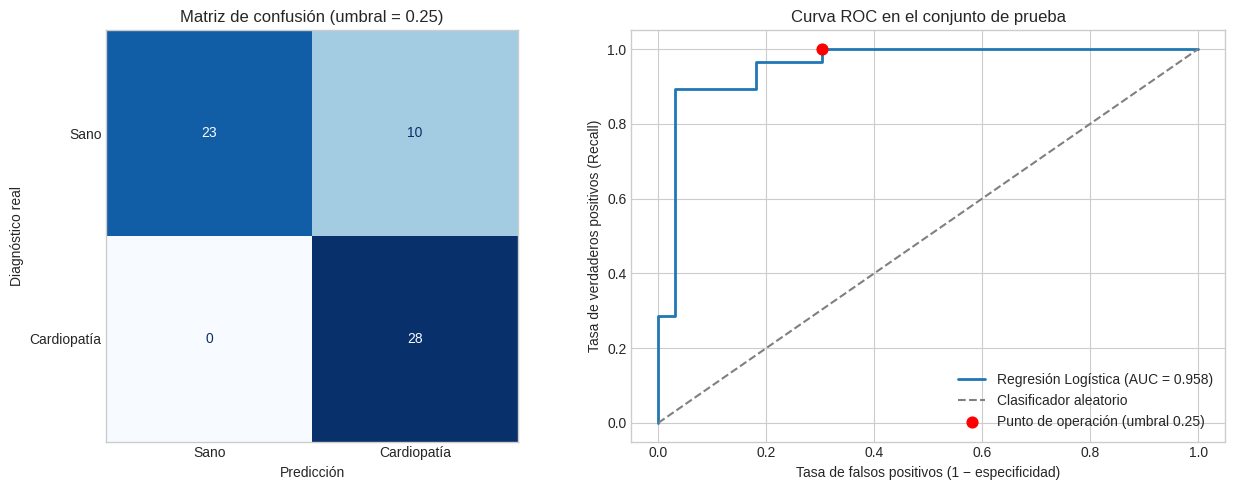

In [ ]:
# EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (se ejecuta UNA sola vez)
# El modelo y el umbral ya quedaron decididos con validación cruzada.
# Aquí solo se mide su desempeño en 61 pacientes que nunca participaron
# en ninguna decisión. La columna "umbral 0.5" es solo una referencia.

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay

# modelo_final fue reajustado por GridSearchCV con los 242 pacientes de entrenamiento
proba_test = modelo_final.predict_proba(X_test)[:, 1]

def resumen_metricas(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        'Accuracy': accuracy_score(y_real, pred),
        'Recall (sensibilidad)': tp / (tp + fn),
        'Especificidad': tn / (tn + fp),
        'Precision': precision_score(y_real, pred),
        'F1-Score': f1_score(y_real, pred),
        'ROC-AUC': roc_auc_score(y_real, proba),
        'Falsos negativos': fn,
        'Falsos positivos': fp,
    }

tabla_test = pd.DataFrame({
    f'Umbral {UMBRAL} (seleccionado)': resumen_metricas(y_test, proba_test, UMBRAL),
    'Umbral 0.5 (referencia)': resumen_metricas(y_test, proba_test, 0.5),
}).T
print("=== DESEMPEÑO EN EL CONJUNTO DE PRUEBA (61 pacientes) ===")
display(tabla_test.round(3))

# --- Gráficos: matriz de confusión y curva ROC reales ---
pred_test = (proba_test >= UMBRAL).astype(int)
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(cm, display_labels=['Sano', 'Cardiopatía']).plot(
    cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title(f'Matriz de confusión (umbral = {UMBRAL})')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Diagnóstico real')
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, proba_test)
auc_test = roc_auc_score(y_test, proba_test)
axes[1].plot(fpr, tpr, linewidth=2, label=f'Regresión Logística (AUC = {auc_test:.3f})')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Clasificador aleatorio')
axes[1].scatter(fp / (fp + tn), tp / (tp + fn), color='red', s=60, zorder=3,
                label=f'Punto de operación (umbral {UMBRAL})')
axes[1].set_xlabel('Tasa de falsos positivos (1 − especificidad)')
axes[1].set_ylabel('Tasa de verdaderos positivos (Recall)')
axes[1].set_title('Curva ROC en el conjunto de prueba')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Análisis e Interpretación de los Resultados**

La evaluación se realizó **una sola vez**, sobre 61 pacientes que no participaron en la selección del modelo, de los hiperparámetros ni del umbral.

* **Matriz de confusión (umbral 0.25):** 28 verdaderos positivos, 23 verdaderos negativos, 0 falsos negativos y 10 falsos positivos. Todos los pacientes con cardiopatía del conjunto de prueba fueron identificados. 10 de los 33 pacientes sanos (≈30%) recibieron una alerta que requeriría exámenes de confirmación.
* **Capacidad de discriminación:** ROC-AUC = 0.958. El punto rojo de la curva ROC muestra la posición de operación elegida: sensibilidad máxima con una tasa de falsos positivos cercana al 30%.
* **Efecto del umbral:** frente al umbral de referencia de 0.5, el umbral de 0.25 elimina los 2 falsos negativos a cambio de 4 falsos positivos adicionales. Es el mismo intercambio observado en la validación cruzada, lo que confirma la coherencia de la decisión.
* **Cautela en la interpretación:**
Un Recall de 1.000 sobre 28 pacientes no implica una sensibilidad perfecta. Con una muestra tan pequeña, el intervalo de confianza al 95% (Wilson) va aproximadamente de **0.88 a 1.00**.
El ROC-AUC del test (0.958) supera al de la validación cruzada (0.907 ± 0.018), lo que indica que esta partición de prueba resultó relativamente favorable. **La validación cruzada se considera la estimación más representativa del desempeño esperado** ante pacientes nuevos: Recall ≈ 0.91 y Precision ≈ 0.70 con el umbral seleccionado.

## **Interpretabilidad del Modelo: Coeficientes de la Regresión Logística**

,Característica,Coeficiente,Odds ratio
0,sexo,1.288,3.626
1,num_vasos_principales,1.115,3.051
2,tipo_dolor_pecho_4.0,0.968,2.632
3,talasemia_7.0,0.813,2.255
4,tipo_dolor_pecho_1.0,-0.641,0.527
5,pendiente_st_2.0,0.594,1.811
6,talasemia_3.0,-0.593,0.553
7,angina_ejercicio,0.543,1.721
8,tipo_dolor_pecho_3.0,-0.482,0.617
9,pendiente_st_1.0,-0.474,0.622


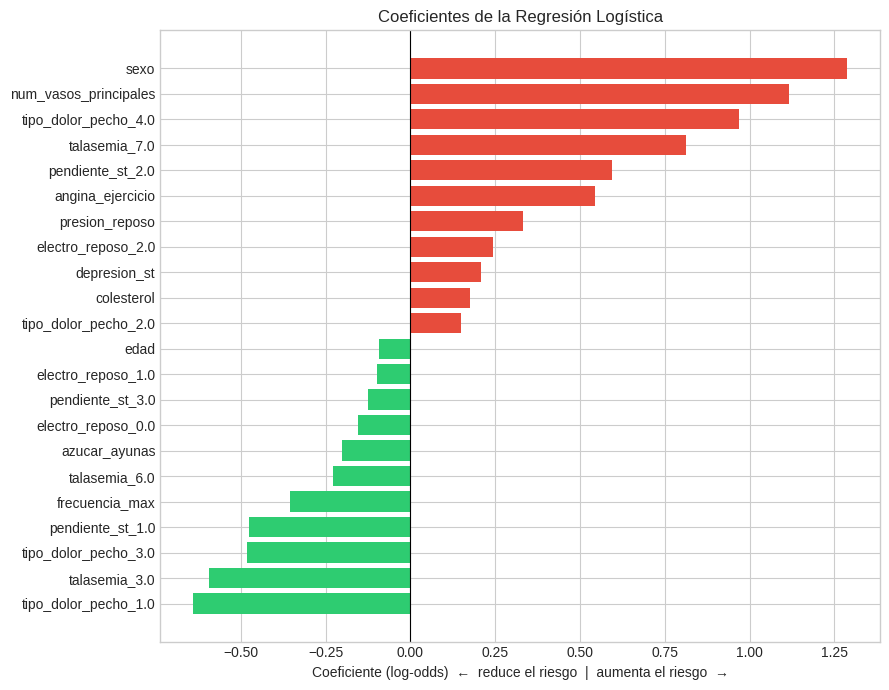

In [ ]:
# INTERPRETABILIDAD: COEFICIENTES DE LA REGRESIÓN LOGÍSTICA
# Cada coeficiente indica cómo cambia el riesgo (en escala log-odds) cuando
# la característica aumenta. Positivo = aumenta el riesgo; negativo = lo reduce.
# El odds ratio (e^coef) expresa cuántas veces se multiplican las probabilidades
# relativas (odds) de cardiopatía.

nombres = (modelo_final.named_steps['prep'].get_feature_names_out()
           .astype(str))
nombres = [n.split('__', 1)[1] for n in nombres]          # quitar prefijos cont__, nom__...
coeficientes = modelo_final.named_steps['clf'].coef_[0]

tabla_coef = pd.DataFrame({
    'Característica': nombres,
    'Coeficiente': coeficientes,
    'Odds ratio': np.exp(coeficientes),
}).sort_values('Coeficiente', key=abs, ascending=False).reset_index(drop=True)

display(tabla_coef.round(3))

# Gráfico: rojo = aumenta el riesgo, verde = lo reduce
orden = tabla_coef.sort_values('Coeficiente')
colores = ['#e74c3c' if c > 0 else '#2ecc71' for c in orden['Coeficiente']]

plt.figure(figsize=(9, 7))
plt.barh(orden['Característica'], orden['Coeficiente'], color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes de la Regresión Logística')
plt.xlabel('Coeficiente (log-odds)  ←  reduce el riesgo  |  aumenta el riesgo  →')
plt.tight_layout()
plt.show()

**Análisis e Interpretación de los Resultados**

En la Regresión Logística, cada coeficiente indica el efecto de una característica **manteniendo constantes las demás** (efecto ajustado). Un coeficiente positivo aumenta el riesgo predicho y uno negativo lo reduce. El odds ratio (OR = $e^{\beta}$) indica cuántas veces se multiplican las odds de cardiopatía.

**Factores que más aumentan el riesgo:**

* **Sexo masculino:** OR ≈ 3.63. A igualdad de las demás variables, las odds de cardiopatía de un hombre son aproximadamente 3.6 veces las de una mujer.
* **Número de vasos principales:** OR ≈ 3.05 por cada desviación estándar (≈1 vaso adicional coloreado por fluoroscopia).
* **Dolor torácico asintomático (tipo 4):** coeficiente +0.97. Confirma lo observado en el EDA: la ausencia de dolor no descarta la enfermedad (isquemia silente).
* **Talasemia con defecto reversible (7):** +0.81, frente a −0.59 del resultado normal (3).
* **Angina inducida por ejercicio** (OR ≈ 1.72) y **pendiente plana del ST** (+0.59).

**Factores asociados a menor riesgo:**

* **Frecuencia cardíaca máxima:** OR ≈ 0.70 por desviación estándar (≈23 lpm). Una mayor capacidad de esfuerzo se asocia con menor riesgo.
* **Angina típica (tipo 1) y pendiente ascendente del ST (1)**, ambas con coeficientes negativos.

**Coherencia con el análisis exploratorio:** las variables más influyentes en el modelo (vasos, talasemia, tipo de dolor, angina, frecuencia máxima y sexo) coinciden con las que mostraron mayor capacidad de separación en el análisis bivariado. La glucemia en ayunas y el colesterol, que casi no separaban los grupos en el EDA, también tienen coeficientes pequeños en el modelo.

**Resultados que requieren explicación:**

* **Edad (coeficiente ≈ −0.09, prácticamente nulo):** en el EDA los enfermos eran algo mayores. El modelo, sin embargo, ya incorpora variables que cambian con la edad, como la frecuencia máxima o el número de vasos. Una vez consideradas, la edad aporta poca información adicional. Es un ejemplo de por qué un coeficiente ajustado puede diferir de una comparación simple.
* **Talasemia con defecto fijo (6) con coeficiente negativo:** con One-Hot Encoding sin categoría de referencia, cada coeficiente debe leerse **en relación con las demás categorías de la misma variable.** El defecto fijo (−0.23) queda por encima del normal (−0.59) y por debajo del reversible (+0.81), lo que conserva el orden de riesgo del EDA. Además, esta categoría tiene pocos pacientes.

**Limitaciones de la interpretación:**

* Las variables continuas están escaladas: su coeficiente corresponde a un aumento de una desviación estándar. Las binarias corresponden a un cambio de 0 a 1. Por eso las magnitudes no son directamente comparables entre ambos tipos.
* La regularización L2 (C=1) reduce ligeramente la magnitud de los coeficientes.
* Los coeficientes describen asociaciones en esta muestra, no relaciones causales.

##**Exportación del Modelo para el Despliegue en Streamlit**

In [ ]:
# EXPORTACIÓN DEL MODELO Y DE LAS EVIDENCIAS PARA STREAMLIT
# Se guarda el PIPELINE COMPLETO (imputación + escalado + One-Hot + modelo):
# así la app aplica exactamente el mismo preprocesamiento aprendido en entrenamiento.
# Todas las métricas y gráficos de la app se leen de 'metricas_modelo.json',
# de modo que ningún número se escribe a mano.

import json
import joblib
import sklearn

# 1. Modelo: un solo archivo (ya no se necesita un escalador por separado)
joblib.dump(modelo_final, 'modelo_cardiaco.pkl')

# 2. Métricas de validación cruzada del modelo seleccionado
res_lr = busquedas["Regresión Logística"].cv_results_
i_lr = busquedas["Regresión Logística"].best_index_
metricas_cv = {m: {'media': float(res_lr[f'mean_test_{m}'][i_lr]),
                   'desviacion': float(res_lr[f'std_test_{m}'][i_lr])}
               for m in metricas}

# 3. Evidencias del conjunto de prueba con el umbral seleccionado
metricas_test = {k: float(v) for k, v in
                 resumen_metricas(y_test, proba_test, UMBRAL).items()}

evidencias = {
    'modelo': 'Regresión Logística',
    'hiperparametros': {k.replace('clf__', ''): v
                        for k, v in busquedas["Regresión Logística"].best_params_.items()},
    'umbral': UMBRAL,
    'version_sklearn': sklearn.__version__,
    'n_entrenamiento': int(len(X_train)),
    'n_prueba': int(len(X_test)),
    'metricas_cv': metricas_cv,
    'umbral_cv': {'recall': float(fila['Recall']), 'precision': float(fila['Precision'])},
    'metricas_test': metricas_test,
    'matriz_confusion': confusion_matrix(y_test, pred_test).tolist(),   # [[TN, FP], [FN, TP]]
    'roc': {'fpr': fpr.tolist(), 'tpr': tpr.tolist(), 'auc': float(auc_test)},
    'coeficientes': dict(zip(tabla_coef['Característica'],
                             tabla_coef['Coeficiente'].astype(float))),
    # Rangos observados en entrenamiento: la app los usa para advertir extrapolación
    'rangos_entrenamiento': {c: [float(X_train[c].min()), float(X_train[c].max())]
                             for c in continuas},
    'comparacion_modelos_cv': {nombre: float(b.best_score_) for nombre, b in busquedas.items()},
}

with open('metricas_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(evidencias, f, ensure_ascii=False, indent=2)

# 4. Verificación: recargar el modelo y comprobar que predice igual
modelo_recargado = joblib.load('modelo_cardiaco.pkl')
assert np.allclose(modelo_recargado.predict_proba(X_test)[:, 1], proba_test)

print("✅ Archivos generados: 'modelo_cardiaco.pkl' y 'metricas_modelo.json'")
print(f"   Versión de scikit-learn usada: {sklearn.__version__}  (anótala para requirements.txt)")

✅ Archivos generados: 'modelo_cardiaco.pkl' y 'metricas_modelo.json'
   Versión de scikit-learn usada: 1.6.1  (anótala para requirements.txt)


# **Conclusiones**


**1. Modelo seleccionado:** Regresión Logística (C=1) dentro de un pipeline de preprocesamiento sin fuga de información. Se eligió por obtener el mayor ROC-AUC en validación cruzada (0.907 ± 0.018), presentar el menor sobreajuste y ofrecer coeficientes interpretables. Random Forest (0.901) y KNN (0.890) tuvieron desempeños cercanos.

**2. Umbral clínico:** el umbral de decisión se redujo de 0.5 a 0.25, para alcanzar una sensibilidad mínima de 0.90 en validación cruzada (Recall 0.91; Precision 0.70).

**3. Desempeño en prueba (61 pacientes):** Recall de 1.00 (28/28; IC 95% ≈ 0.88–1.00), especificidad de 0.70 y ROC-AUC de 0.958. Como este conjunto resultó relativamente favorable, la validación cruzada se considera la estimación más representativa.

**4. Rol del sistema:** por su perfil de alta sensibilidad y precisión moderada, el modelo es adecuado como herramienta de tamizaje para priorizar exámenes confirmatorios. No reemplaza el diagnóstico médico.

**5. Limitaciones:** muestra pequeña (303 pacientes) y de un único centro (Cleveland), que limita la generalización a otras poblaciones. Las relaciones encontradas son asociaciones, no causas. Un trabajo futuro debería validar el modelo con datos externos, por ejemplo con los otros centros del repositorio UCI.

# **Referencias**

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). *Heart disease* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.